# Adding a perturbation

*Section "Adding a perturbation" of the paper.*

In the navigation benchmarks the target (the focus of expansion, FoE) only diffuses slowly. Here a second
stage is added: **abrupt, exogenous perturbations** of the position of the FoE, that is sudden displacements of
the gaze from the axis, in the same tunnel. They probe the robustness of a model to a mismatch between what it
predicted and what it sees, in the spirit of the sensorimotor-mismatch experiments used to study predictive
processing in the visual cortex. This is the benchmark **AVB3** (`perturb`).

## Contents

1. [The model](#The-model)
2. [The perturbation signal](#The-perturbation-signal)
3. [Recovery after a jump](#Recovery-after-a-jump)
4. [Sweep of the hazard rate and of the amplitude](#Sweep-of-the-hazard-rate-and-of-the-amplitude), with [responsiveness against noise](#Responsiveness-against-noise)
5. [Checks](#Checks)


## The model

The perturbation is the sum of two independent components, on top of the mean $\bar h$ of the trial:

$$h(t) = \bar h + x(t) + \sum_{i} a_i\,\Theta(t - t_i).$$

* $x(t)$ is the **slow Langevin diffusion** of the previous notebook (time constant $\tau$, stationary amplitude
  $\sigma_\mathrm{OU}$). It is always present.
* The **jumps** arrive at the times $t_i$ of a Poisson process of **hazard rate** $\lambda$ (perturbations per
  second): in a step of duration $\Delta t$ a jump occurs with the probability $1 - e^{-\lambda \Delta t}$,
  so that the intervals between jumps are exponentially distributed with the mean $1/\lambda$. Their
  amplitudes $a_i$ are drawn from a Gaussian of mean 0 and **standard deviation** $\sigma_\mathrm{jump}$. A jump
  is permanent: $\Theta$ is the Heaviside step.

A jump is seen as a sudden displacement of the FoE in the image. The model brings it back to the centre by
rotating its gaze, and the quantities of interest are the root-mean-square error of the FoE, its **peak**
after a jump and the **recovery time**: the time after a jump at which the error falls below a threshold.

| Symbol | Name in the code | Default value | Role |
|--------|------------------|---------------|------|
| $\tau$ | `Perturbation.tau` | 1 s | time constant of the diffusion |
| $\sigma_\mathrm{OU}$ | `Perturbation.sigma_ou` | 2 deg (cylinder) | stationary amplitude of the diffusion |
| $\lambda$ | `Perturbation.hazard_rate` | 0 s$^{-1}$ (no jump) | hazard rate of the jumps |
| $\sigma_\mathrm{jump}$ | `Perturbation.sigma_jump` | 0 deg | standard deviation of the amplitude of a jump |
| $\kappa$ | `GazeStabilisationModel.gain` | 0.4 | fraction of the estimated FoE offset corrected at each step |
| | `n_steps` | 300 | number of steps of a trial (at 60 Hz) |

In [1]:
import pathlib
import sys

ROOT = pathlib.Path.cwd().parent          # the repository, when the package is not installed
sys.path.insert(0, str(ROOT))

import numpy as np

import ActiveVisionBenchmark as avb
from functools import partial

cached = partial(avb.cached, cache_dir=ROOT / "cache")
save = partial(avb.save_figure, directory=ROOT / "figures")

# Colour-blind safe palette (Okabe-Ito)
BLUE, ORANGE, RED, GREY = "#0072B2", "#E69F00", "#D55E00", "#666666"

import dataclasses
import os

N_JOBS = os.cpu_count()
SEED = 7
DT = 1 / 60

## The perturbation signal

The two components of a trajectory, for jumps at a hazard rate of 0.3 per second and a standard deviation of 5 degrees:

[]

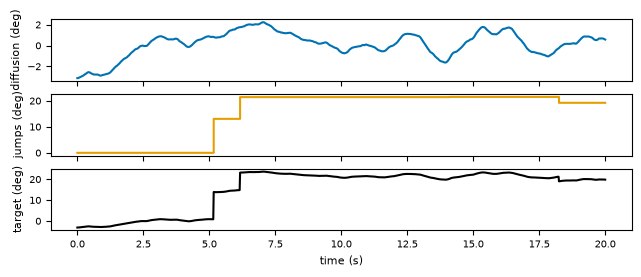

In [2]:
perturbation = avb.Perturbation(dt=DT, tau=1.0, sigma_ou=2.0, hazard_rate=0.3, sigma_jump=5.0)
n_steps = 20 * 60
diffusion, jumps = perturbation.components(n_steps, seed=11)
time = np.arange(n_steps + 1) * DT

fig, axes = avb.new_figure(16, 6.5, 3, 1, sharex=True)
axes[0].plot(time, diffusion, color=BLUE)
axes[0].set_ylabel("diffusion (deg)")
axes[1].step(time, jumps, color=ORANGE, where="post")
axes[1].set_ylabel("jumps (deg)")
axes[2].plot(time, diffusion + jumps, color="k")
axes[2].set_ylabel("target (deg)")
axes[2].set_xlabel("time (s)")
save(fig, "03_signal")

## Recovery after a jump

The tunnel task is now perturbed by jumps. The same three models as before are compared, on trials of 15 s:
a fixed gaze, the `DummyController` (noisy and delayed true FoE) and `GazeStabilisationModel` (estimation from
the images). The figure shows one trial, with the instants of the jumps.

[]

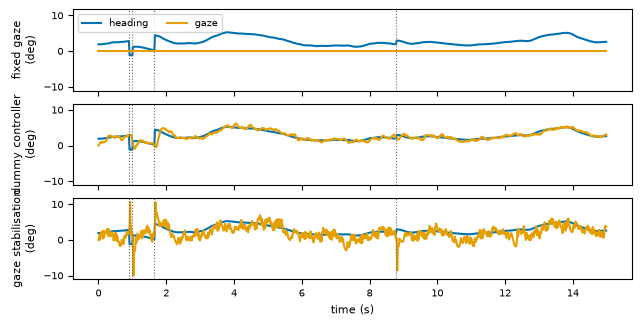

In [3]:
JUMPS = dict(hazard_rate=0.3, sigma_jump=5.0)
CYLINDER = dict(size=128, noise_std=0.01, n_steps=900)
DUMMY = dict(noise_std=1.0, lag=3, gain=0.15)
STABILISE = dict(gain=0.4)

perturbed = avb.CylinderTask(avb.MotionCloudStimulus(),
                             perturbation=avb.Perturbation(dt=DT, tau=1.0, sigma_ou=2.0, **JUMPS), **CYLINDER)
models = {
    "fixed gaze": avb.FixedGazeModel(),
    "dummy controller": avb.DummyController(**DUMMY),
    "gaze stabilisation": avb.GazeStabilisationModel(**STABILISE),
}

def jump_steps(task, trial):
    """Steps at which a jump of the heading occurs in a trial."""
    pert = dataclasses.replace(task.perturbation, mean=trial.heading_offset)
    _, jumps = pert.components(task.n_steps, seed=trial.seed + 1)
    return np.nonzero(np.diff(jumps))[0]

def rollout(task, model, trial):
    obs = task.reset(trial)
    model.reset(trial.seed)
    t, heading, gaze, done = [], [], [], False
    while not done:
        t.append(obs.t)
        heading.append(obs.info["heading"])           # ground truth, for the figure only
        gaze.append(obs.gaze)
        obs, done, _ = task.step(model.act(obs))
    return np.array(t), np.array(heading), np.array(gaze)

trial = perturbed.generate_trial(5)
fig, axes = avb.new_figure(16, 8, 3, 1, sharex=True, sharey=True)
for ax, (name, model) in zip(axes, models.items()):
    t, heading, gaze = rollout(perturbed, model, trial)
    ax.plot(t, heading, color=BLUE, label="heading")
    ax.plot(t, gaze, color=ORANGE, label="gaze")
    for k in jump_steps(perturbed, trial):
        ax.axvline(k * DT, color=GREY, ls=":", lw=0.8)
    ax.set_ylabel(f"{name}\n(deg)")
axes[0].legend(loc="upper left", ncols=2)
axes[-1].set_xlabel("time (s)")
save(fig, "03_trajectories")

### Benchmark AVB3: `perturb`

The tunnel of AVB2 with **abrupt jumps of the FoE** added to its slow diffusion. The model has to resist the jumps:
its gaze must come back to the axis after each of them. This benchmark is **active**. The jumps are permanent
(`jump_tau=None`): a jump is a sudden and lasting change of the heading.

| Symbol | Name in the code | Value | Role |
|--------|------------------|-------|------|
| $\lambda$ | `perturbation.hazard_rate` | 0.3 s$^{-1}$ | rate of the jumps (a Poisson process) |
| $\sigma_\mathrm{jump}$ | `perturbation.sigma_jump` | 5 deg | standard deviation of the amplitude of a jump |
| $\tau$, $\sigma_\mathrm{OU}$ | `perturbation.tau`, `perturbation.sigma_ou` | 1 s, 2 deg | slow diffusion, as in AVB2 |
| | `n_steps` | 900 (15 s) | steps of a trial, to see several jumps |
| | `size`, `noise_std`, `heading_lag` | 128 pixels, 0.01, `None` | as in AVB2 |
| | `THRESHOLD` | 1 deg | error under which the target is recovered |

**Dataset:** 24 trials, seed 7. **Reference models:** `FixedGazeModel` and `GazeStabilisationModel` (gain $\kappa = 0.4$);
`DummyController` is a test double. **Metrics:** RMS error of the FoE (deg) and recovery time after a jump (s).
The sweep of $\lambda$ and $\sigma_\mathrm{jump}$ below is a **study of sensitivity**: it is not part of the definition
of the benchmark. The cell below prints the values that the task actually uses.


In [4]:
for name in ("size", "visual_angle", "radius", "period", "speed", "dt", "n_steps", "depth_exponent", "noise_std",
             "heading_lag"):
    print(f"{name:17s} {getattr(perturbed, name)}")
print(f"{'perturbation':17s} {perturbed.perturbation}")
print(f"{'seed':17s} {SEED}")

size              (128, 128)
visual_angle      45.0
radius            1.0
period            10.0
speed             6.0
dt                0.016666666666666666
n_steps           900
depth_exponent    2.0
noise_std         0.01
heading_lag       None
perturbation      Perturbation(dt=0.016666666666666666, tau=1.0, sigma_ou=2.0, mean=0.0, hazard_rate=0.3, sigma_jump=5.0, limit=None, seed=None, jump_tau=None)
seed              7


**Recovery time.** The error of the FoE is averaged around the jumps that are isolated (no other jump in the
window), over a dataset of trials. For a model that is blind to the jump (a fixed gaze) the error stays at the
amplitude of the jump; a controller brings it back, at a speed that depends on its gain and on the quality of its
estimate.

fixed gaze           peak 7.38 deg, recovery below 1 deg: never
dummy controller     peak 4.33 deg, recovery below 1 deg: 0.15 s
gaze stabilisation   peak 8.57 deg, recovery below 1 deg: 2.08 s


[]

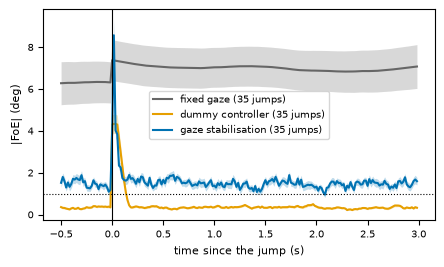

In [5]:
N_TRIALS = avb.scaled(24, 4)
PRE, POST = 30, 180                       # steps before and after a jump
THRESHOLD = 1.0                           # deg, error under which the target is recovered

bench = avb.ActiveBenchmark(perturbed)
trials = bench.generate_dataset(N_TRIALS, seed=SEED)
results = cached("03_recovery", dict(cylinder=CYLINDER, jumps=JUMPS, dummy=DUMMY, stabilise=STABILISE, n_trials=N_TRIALS, seed=SEED),
                 lambda: bench.evaluate(trials, models, n_jobs=N_JOBS))

def event_triggered(result):
    """Error of the FoE around the isolated jumps of all the trials (rows: jumps)."""
    windows = []
    for r in result.trial_results:
        steps = jump_steps(perturbed, r.trial)
        for j in steps:
            others = steps[steps != j]
            if j >= PRE and j + POST < len(r.errors) and not np.any((others > j - PRE) & (others < j + POST)):
                windows.append(r.errors[j - PRE: j + POST])
    return np.array(windows)

fig, ax = avb.new_figure(11, 6.5)
lags = (np.arange(-PRE, POST)) * DT
for (name, res), color in zip(results.items(), (GREY, ORANGE, BLUE)):
    windows = event_triggered(res)
    mean, sem = windows.mean(0), windows.std(0) / np.sqrt(len(windows))
    ax.plot(lags, mean, color=color, label=f"{name} ({len(windows)} jumps)")
    ax.fill_between(lags, mean - sem, mean + sem, color=color, alpha=0.25, lw=0)
    after = np.nonzero((lags > 0) & (mean < THRESHOLD))[0]
    recovered = f"{lags[after[0]]:.2f} s" if len(after) else "never"
    print(f"{name:20s} peak {mean.max():.2f} deg, recovery below {THRESHOLD:g} deg: {recovered}")
ax.axhline(THRESHOLD, color="k", ls=":", lw=0.8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("time since the jump (s)")
ax.set_ylabel("|FoE| (deg)")
ax.legend()
save(fig, "03_recovery")

## Sweep of the hazard rate and of the amplitude

The error of a fixed gaze grows with both the rate and the amplitude of the jumps, because each jump
displaces the FoE for good. A controller that estimates the FoE from the images keeps the error low as long as the
jumps are not too frequent for it to recover between two of them.

[]

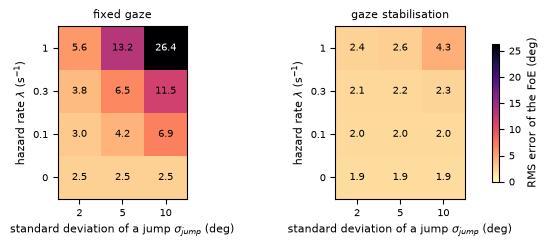

In [6]:
RATES, AMPLITUDES = [0.0, 0.1, 0.3, 1.0], [2.0, 5.0, 10.0]
N_SWEEP = avb.scaled(8, 3)
SWEEP_STEPS = 600
pair = {k: models[k] for k in ("fixed gaze", "gaze stabilisation")}

def sweep():
    out = np.zeros((len(pair), len(RATES), len(AMPLITUDES)))
    for i, rate in enumerate(RATES):
        for j, amplitude in enumerate(AMPLITUDES):
            task = avb.CylinderTask(avb.MotionCloudStimulus(), size=128, noise_std=0.01, n_steps=SWEEP_STEPS,
                                    perturbation=avb.Perturbation(dt=DT, tau=1.0, sigma_ou=2.0, hazard_rate=rate, sigma_jump=amplitude))
            bench = avb.ActiveBenchmark(task)
            res = bench.evaluate(bench.generate_dataset(N_SWEEP, seed=SEED), pair, n_jobs=N_JOBS)
            for k, name in enumerate(pair):
                out[k, i, j] = res[name].rms_error
    return out

errors = cached("03_sweep", dict(rates=RATES, amplitudes=AMPLITUDES, n_trials=N_SWEEP, steps=SWEEP_STEPS, stabilise=STABILISE, seed=SEED), sweep)

fig, axes = avb.new_figure(16, 6, 1, 2)
vmax = errors.max()
for ax, name, grid in zip(axes, pair, errors):
    image = ax.imshow(grid, origin="lower", cmap="magma_r", vmin=0, vmax=vmax)
    ax.set_xticks(range(len(AMPLITUDES)), [f"{a:g}" for a in AMPLITUDES])
    ax.set_yticks(range(len(RATES)), [f"{r:g}" for r in RATES])
    ax.set_xlabel(r"standard deviation of a jump $\sigma_{jump}$ (deg)")
    ax.set_ylabel(r"hazard rate $\lambda$ (s$^{-1}$)")
    ax.set_title(name)
    for i in range(len(RATES)):
        for j in range(len(AMPLITUDES)):
            ax.text(j, i, f"{grid[i, j]:.1f}", ha="center", va="center", color="w" if grid[i, j] > 0.55 * vmax else "k", fontsize=7)
fig.colorbar(image, ax=axes, label="RMS error of the FoE (deg)", shrink=0.8)
save(fig, "03_sweep")

### Responsiveness against noise

With jumps present, a higher gain $\kappa$ recovers faster but passes more of the noise of the estimate on to the
gaze, and too high a gain makes the loop oscillate. The error is minimal for an intermediate gain.

[]

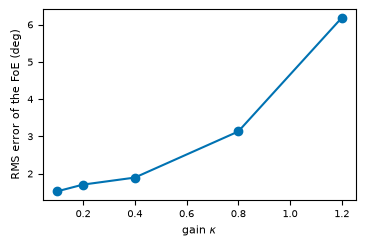

In [7]:
GAINS = [0.1, 0.2, 0.4, 0.8, 1.2]
N_GAIN = avb.scaled(8, 3)

def gain_sweep():
    bench = avb.ActiveBenchmark(perturbed)
    trials = bench.generate_dataset(N_GAIN, seed=SEED + 1)
    return [bench.run(avb.GazeStabilisationModel(gain=g), trials, n_jobs=N_JOBS).rms_error for g in GAINS]

by_gain = cached("03_gain", dict(gains=GAINS, cylinder=CYLINDER, jumps=JUMPS, n_trials=N_GAIN, seed=SEED + 1), gain_sweep)
fig, ax = avb.new_figure(9, 6)
ax.plot(GAINS, by_gain, "o-", color=BLUE)
ax.set_xlabel(r"gain $\kappa$")
ax.set_ylabel("RMS error of the FoE (deg)")
save(fig, "03_gain")

## Checks

**1. The jumps follow their law.** The number of jumps per second is the hazard rate $\lambda$, the intervals between
jumps are exponentially distributed with the mean $1/\lambda$ and the amplitudes are Gaussian with the
standard deviation $\sigma_\mathrm{jump}$. With no hazard rate there is no jump.

rate 0.496 per second (hazard rate 0.5); mean interval 2.02 s (1/rate 2.00 s); amplitude std 3.04 deg (sigma 3.0)
number of jumps with a hazard rate of 0: 0


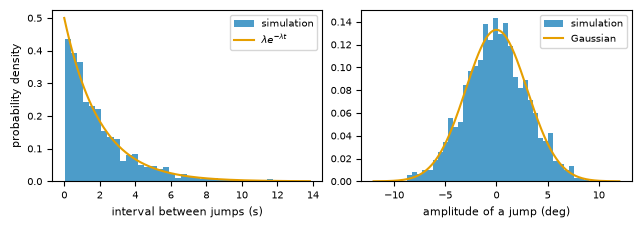

In [8]:
RATE, AMPLITUDE = 0.5, 3.0
long_run = avb.Perturbation(dt=DT, tau=1.0, sigma_ou=0.0, hazard_rate=RATE, sigma_jump=AMPLITUDE)
duration = avb.scaled(3000, 200)                                   # seconds
_, steps = long_run.components(duration * 60, seed=1)
change = np.diff(steps)
times, amplitudes = np.nonzero(change)[0] * DT, change[change != 0]
intervals = np.diff(times)

fig, axes = avb.new_figure(16, 5.5, 1, 2)
axes[0].hist(intervals, bins=40, density=True, color=BLUE, alpha=0.7, label="simulation")
grid = np.linspace(0, intervals.max(), 200)
axes[0].plot(grid, RATE * np.exp(-RATE * grid), color=ORANGE, label=r"$\lambda e^{-\lambda t}$")
axes[0].set_xlabel("interval between jumps (s)")
axes[0].set_ylabel("probability density")
axes[0].legend()
axes[1].hist(amplitudes, bins=40, density=True, color=BLUE, alpha=0.7, label="simulation")
grid = np.linspace(-4 * AMPLITUDE, 4 * AMPLITUDE, 200)
axes[1].plot(grid, np.exp(-grid**2 / (2 * AMPLITUDE**2)) / (AMPLITUDE * np.sqrt(2 * np.pi)), color=ORANGE, label="Gaussian")
axes[1].set_xlabel("amplitude of a jump (deg)")
axes[1].legend()
save(fig, "03_checks_jumps")

print(f"rate {len(times) / duration:.3f} per second (hazard rate {RATE}); mean interval {intervals.mean():.2f} s (1/rate {1 / RATE:.2f} s); "
      f"amplitude std {amplitudes.std():.2f} deg (sigma {AMPLITUDE})")
none = avb.Perturbation(dt=DT, tau=1.0, sigma_ou=0.0, hazard_rate=0.0, sigma_jump=AMPLITUDE).components(60 * 600, seed=1)[1]
print("number of jumps with a hazard rate of 0:", int(np.count_nonzero(np.diff(none))))

**2. The jumps are seen in the image.** A jump of the offset between the gaze and the axis displaces the FoE in the next frame by the amplitude
of the jump: here the FoE (the dark centre of the tunnel) before and after a jump of 8 degrees.

[]

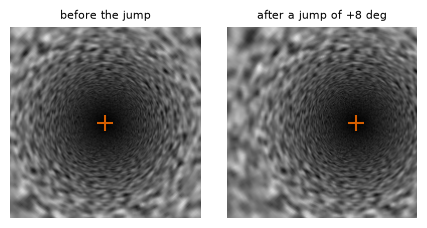

In [9]:
tunnel = avb.CylinderTask(avb.MotionCloudStimulus(), size=192, depth_exponent=1.0)
fig, axes = avb.new_figure(11, 5.5, 1, 2)
for ax, heading in zip(axes, (0.0, 8.0)):
    image = tunnel.render(avb.Pose(heading=heading), seed=0)[0].cpu().numpy()
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.plot((heading / tunnel.visual_angle + 0.5) * 191, 95.5, "+", color=RED, ms=12, mew=1.5)
    ax.set_title("before the jump" if heading == 0 else "after a jump of +8 deg")
    ax.axis("off")
save(fig, "03_checks_jump_image")